# 09 FMF detection threshold: 12×MAD or 10×MAD, with or without the 0.20 floor (decision D23)

A time step becomes a detection when three tests pass:
1. **MAD test.** The template's network CC exceeds its median plus K times its median absolute deviation (MAD). This is computed per day and per station-configuration segment; Haenam used K = 12.
2. **Floor test.** The network CC is at least 0.20. The floor was added in Buan, where many stations make the MAD small, so that 12×MAD alone would fall to noise level.
3. **Station test.** At least 4 stations are present.

Hits closer than 4 s are merged into one detection.

You suspected that the floor, and perhaps K = 12, miss small genuine events at Imsil. Four catalogs from the aligned code are compared:

| Variant | MAD factor | Floor |
|---|---|---|
| current | 12 | 0.20 |
| 12×MAD, no floor | 12 | none |
| 10×MAD + floor | 10 | 0.20 |
| 10×MAD, no floor | 10 | none |

The 10×MAD catalogs come from a full re-scan, because hits between 10× and 12× MAD were never stored. The station test and the 4 s merge are unchanged.

**The false-alarm control** is the rest of the period. Every template is a swarm event, so a detection outside the swarm window is either a real event near the swarm or a false alarm. Detections added inside the swarm get the independent PhaseNet+ pick check of notebook 08 and Haenam's detection sets.

In [1]:
import os, sys, glob, functools
import numpy as np, pandas as pd
import multiprocessing as mp, concurrent.futures as cf
DL = '/home/msseo/works/72.2025_Imsil_swarm/DL_detection'; FA = f'{DL}/fmf_aligned'
os.environ.update(FMF_RUN='imsil_5_20H_aligned', FMF_BAND='5,20', FMF_STATION_LIST=f'{FA}/stations_imsil_5_20H.csv', FMF_SEQUENCES='imsil',
                  FMF_TEMPLATE_CSV='imsil_templates_ref25.csv', MAD_SEGMENTED='1', FMF_SNR_MIN='1.2', FMF_MAD_SUBSAMPLE='8', FMF_STEP='1',
                  FMF_WORKERS='16', FMF_GPU_BUDGET='12e9', HELVETICA_DIR='/home/msseo/Download/Helvetica')
sys.path.insert(0, FA)
import config as C, scan, similarity as S
scan.ProcessPoolExecutor = functools.partial(cf.ProcessPoolExecutor, mp_context=mp.get_context('forkserver'))   # fresh loader workers (see README)
import importlib.util
spec = importlib.util.spec_from_file_location('plotstyle', f'{DL}/pipeline/plotstyle.py'); plotstyle = importlib.util.module_from_spec(spec); spec.loader.exec_module(plotstyle)
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from IPython.display import Image, display
CATS = f'{FA}/catalogs'
VAR = {'current (12×MAD, floor 0.20)': f'{CATS}/fmf_imsil_catalog_imsil_5_20H_aligned_seg.csv',
       '12×MAD, no floor': f'{CATS}/fmf_imsil_catalog_imsil_5_20H_aligned_seg_nofloor.csv',
       '10×MAD, floor 0.20': f'{CATS}/fmf_imsil_catalog_imsil_5_20H_aligned_mad10_seg.csv',
       '10×MAD, no floor': f'{CATS}/fmf_imsil_catalog_imsil_5_20H_aligned_mad10_seg_nofloor.csv'}
cat = {k: pd.read_csv(f, parse_dates=['origin']).sort_values('origin').reset_index(drop=True) for k, f in VAR.items()}
sh = S.load_shelly(); ev = [str(e) for e in sh['event_id']]; cusp = list(sh['cuspid'].astype(int)); stations = [str(s) for s in sh['stations']]; prefixes = [str(p) for p in sh['channels']]
z10 = np.load(f'{FA}/templates_cache/imsil_shelly_imsil_5_20H_aligned_mad10.npz', allow_pickle=True)
same_tpl = all(np.array_equal(sh[k], z10[k]) for k in ('P_waveforms', 'S_waveforms', 'P_moveouts', 'S_moveouts', 'P_weights', 'S_weights'))
print('templates of the 10xMAD re-scan identical to the 12xMAD run:', same_tpl)
SW0, SW1 = pd.Timestamp('2025-11-02 19:55'), pd.Timestamp('2025-11-03 01:00')
tsec = lambda x: pd.to_datetime(x).values.astype('datetime64[ns]').astype('int64') / 1e9

templates of the 10xMAD re-scan identical to the 12xMAD run: True


## 1. Where the floor bites: per-template thresholds on 2025-11-02
For each template, the network-CC trace of the swarm day is recomputed exactly as the scan sums it (`similarity.template_cc_day`). The figure shows 12×MAD and 10×MAD of that whole-day trace against the 0.20 floor.

Where the MAD line lies below 0.20, the floor is the threshold actually in force. The catalog used per-segment thresholds; whole-day values are shown for context.

8639801 correlation computations were skipped on the 0-th template. Can be caused by zeros in data, or too low amplitudes (try to increase the gain).


8639675 correlation computations were skipped on the 0-th template. Can be caused by zeros in data, or too low amplitudes (try to increase the gain).


8639801 correlation computations were skipped on the 0-th template. Can be caused by zeros in data, or too low amplitudes (try to increase the gain).


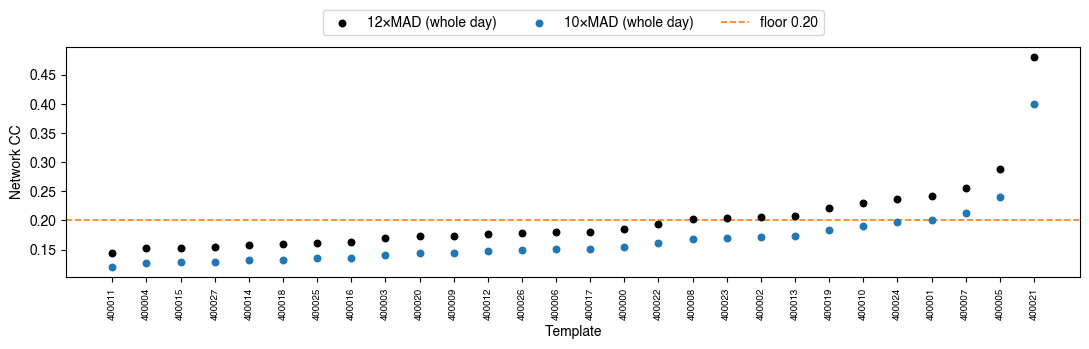

templates whose whole-day 12xMAD is below the floor: 17 of 28; 10xMAD below the floor: 24
12xMAD range 0.144-0.480; 10xMAD range 0.120-0.400


In [2]:
day306 = scan.load_day(stations, prefixes, 2025, 306); thr = []
for k in range(len(ev)):
    res = S.template_cc_day(sh, k, 2025, 306, day=day306)
    if res is not None: thr.append(dict(cuspid=cusp[k], mad=res['mad'], t12=12 * res['mad'], t10=10 * res['mad'], channels=res['n_channels']))
thr = pd.DataFrame(thr).sort_values('t12').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 3.6))
x = np.arange(len(thr)); ax.scatter(x, thr.t12, color='black', s=22, label='12×MAD (whole day)', zorder=3); ax.scatter(x, thr.t10, color='tab:blue', s=22, label='10×MAD (whole day)', zorder=3)
ax.axhline(0.20, color='tab:orange', ls='--', lw=1.2, label='floor 0.20'); ax.set_xticks(x, thr.cuspid, rotation=90, fontsize=7); ax.set_ylabel('Network CC'); ax.set_xlabel('Template')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=True); plt.tight_layout(); plt.show()
print(f'templates whose whole-day 12xMAD is below the floor: {int((thr.t12 < 0.2).sum())} of {len(thr)}; 10xMAD below the floor: {int((thr.t10 < 0.2).sum())}')
print(f'12xMAD range {thr.t12.min():.3f}-{thr.t12.max():.3f}; 10xMAD range {thr.t10.min():.3f}-{thr.t10.max():.3f}')

## 2. Counts

In [3]:
rows = []
for k, c in cat.items():
    sw = c.origin.between(SW0, SW1)
    rows.append(dict(variant=k, detections=len(c), reference=int(c.is_reference.sum()), new=int(c.is_new.sum()), in_swarm_window=int(sw.sum()), outside_swarm_window=int((~sw).sum()),
                     min_cc=round(c.cc.min(), 3)))
cnt = pd.DataFrame(rows).set_index('variant'); display(cnt)
for k, c in cat.items():
    o = c[~c.origin.between(SW0, SW1)]
    if len(o): print(f'{k}: outside the swarm window by date {o.origin.dt.strftime("%Y-%m-%d").value_counts().sort_index().to_dict()}')

,detections,reference,new,in_swarm_window,outside_swarm_window,min_cc
variant,,,,,,
"current (12×MAD, floor 0.20)",187,28,159,187,0,0.202
"12×MAD, no floor",194,28,166,194,0,0.159
"10×MAD, floor 0.20",210,28,182,210,0,0.202
"10×MAD, no floor",235,28,207,234,1,0.129


10×MAD, no floor: outside the swarm window by date {'2025-11-03': 1}


## 3. What each relaxation adds
Detections are compared with the current catalog: a detection counts as added when no current detection lies within 2 s.

12×MAD, no floor: 7 added (inside the swarm window 7), 0 current detections not found
10×MAD, floor 0.20: 23 added (inside the swarm window 23), 0 current detections not found
10×MAD, no floor: 48 added (inside the swarm window 47), 0 current detections not found


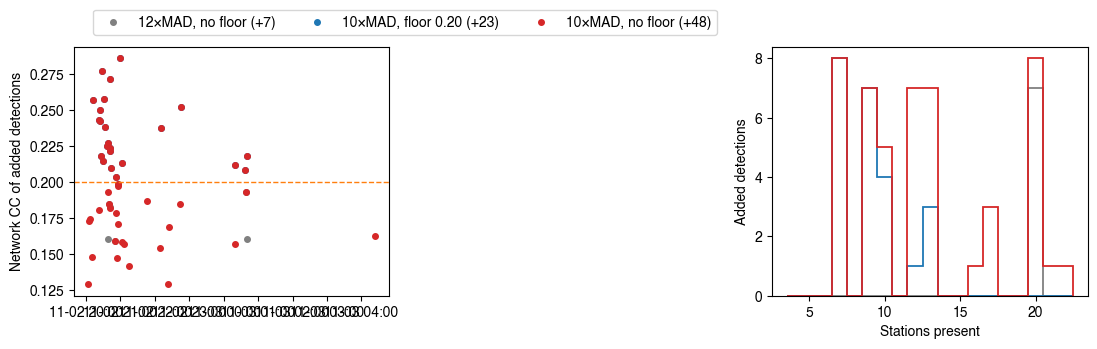

In [4]:
base = cat['current (12×MAD, floor 0.20)']; tb = tsec(base.origin); added = {}
for k, c in cat.items():
    if k.startswith('current'): continue
    tc = tsec(c.origin); m = np.array([np.min(np.abs(tb - t)) > 2 for t in tc]); added[k] = c[m].copy()
    lost = sum(np.min(np.abs(tc - t)) > 2 for t in tb)
    print(f'{k}: {int(m.sum())} added (inside the swarm window {int(c[m].origin.between(SW0, SW1).sum())}), {lost} current detections not found')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for (k, a), col in zip(added.items(), ('0.5', 'tab:blue', 'tab:red')):
    ax[0].scatter(a.origin, a.cc, s=16, color=col, label=f'{k} (+{len(a)})')
    ax[1].hist(a.n_present, bins=np.arange(3.5, 23.5, 1), histtype='step', lw=1.3, color=col)
ax[0].axhline(0.2, color='tab:orange', ls='--', lw=1); ax[0].set_ylabel('Network CC of added detections'); ax[0].xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))
ax[0].legend(loc='lower center', bbox_to_anchor=(1.05, 1.02), ncol=3, frameon=True); ax[1].set_xlabel('Stations present'); ax[1].set_ylabel('Added detections')
plt.tight_layout(); plt.show()

## 4. Independent picks for the added detections
This is the same check as notebook 08 (b): PhaseNet+ picks within 0.25 s (P) or 0.30 s (S) of the arrival times the template predicts, against the same predictions shifted by ±7–17 s. The current catalog's new detections serve as the reference.

In [5]:
days = sorted({(t.year, t.dayofyear) for c in cat.values() for t in c.origin})
picks = pd.concat([pd.read_csv(f, parse_dates=['peak_time']) for y, d in days for f in glob.glob(f'{DL}/models/phasenet_plus/detection_location/{y}/picks/picks_{y}.{d:03d}.csv')], ignore_index=True)
pk_t = {(s, ph): np.sort(tsec(g.peak_time)) for (s, ph), g in picks.groupby(['station', 'phase'])}
SHIFTS = [-17.3, -13.1, -9.7, -7.1, 7.3, 9.9, 13.7, 16.9]
def predicted(ti, origin):
    o = tsec([origin])[0]; out = {}
    for si, ph, ci, mo, n, tw, j in S.channels_of(sh, ti): out.setdefault((stations[si], ph), o + float(sh['ref_s'][ti]) + mo / C.FS + 0.5)
    return out
def matches(pred, shift=0.0):
    m = 0
    for (s, ph), t in pred.items():
        arr = pk_t.get((s, ph)); tol = 0.25 if ph == 'P' else 0.30
        if arr is None or not len(arr): continue
        i = np.searchsorted(arr, t + shift); m += int(any(abs(arr[q] - (t + shift)) <= tol for q in (i - 1, i) if 0 <= q < len(arr)))
    return m
def pick_check(c):
    out = []
    for r in c.itertuples():
        pred = predicted(cusp.index(int(r.template_cuspid)), r.origin); bg = np.mean([matches(pred, s) for s in SHIFTS])
        out.append(dict(origin=r.origin, cc=r.cc, n_present=r.n_present, n_match=matches(pred), expected=bg))
    out = pd.DataFrame(out); out['excess'] = out.n_match - out.expected; return out
PC = {'current new detections': pick_check(base[base.is_new])} | {f'added: {k}': pick_check(a) for k, a in added.items() if len(a)}
tab = pd.DataFrame({k: dict(n=len(v), median_excess=v.excess.median(), share_excess_ge3=(v.excess >= 3).mean()) for k, v in PC.items()}).T
display(tab.round(2))

,n,median_excess,share_excess_ge3
current new detections,159.0,2.75,0.47
"added: 12×MAD, no floor",7.0,0.00,0.14
"added: 10×MAD, floor 0.20",23.0,0.00,0.00
"added: 10×MAD, no floor",48.0,0.00,0.02


## 5. Waveforms of the weakest added detections and of any detection outside the swarm
Haenam's detection sets (`similarity.plot_detection_set`), as in notebooks 07 and 08, for:
- the four lowest-CC detections added by the most relaxed variant (10×MAD, no floor);
- every detection outside the swarm window, up to six.

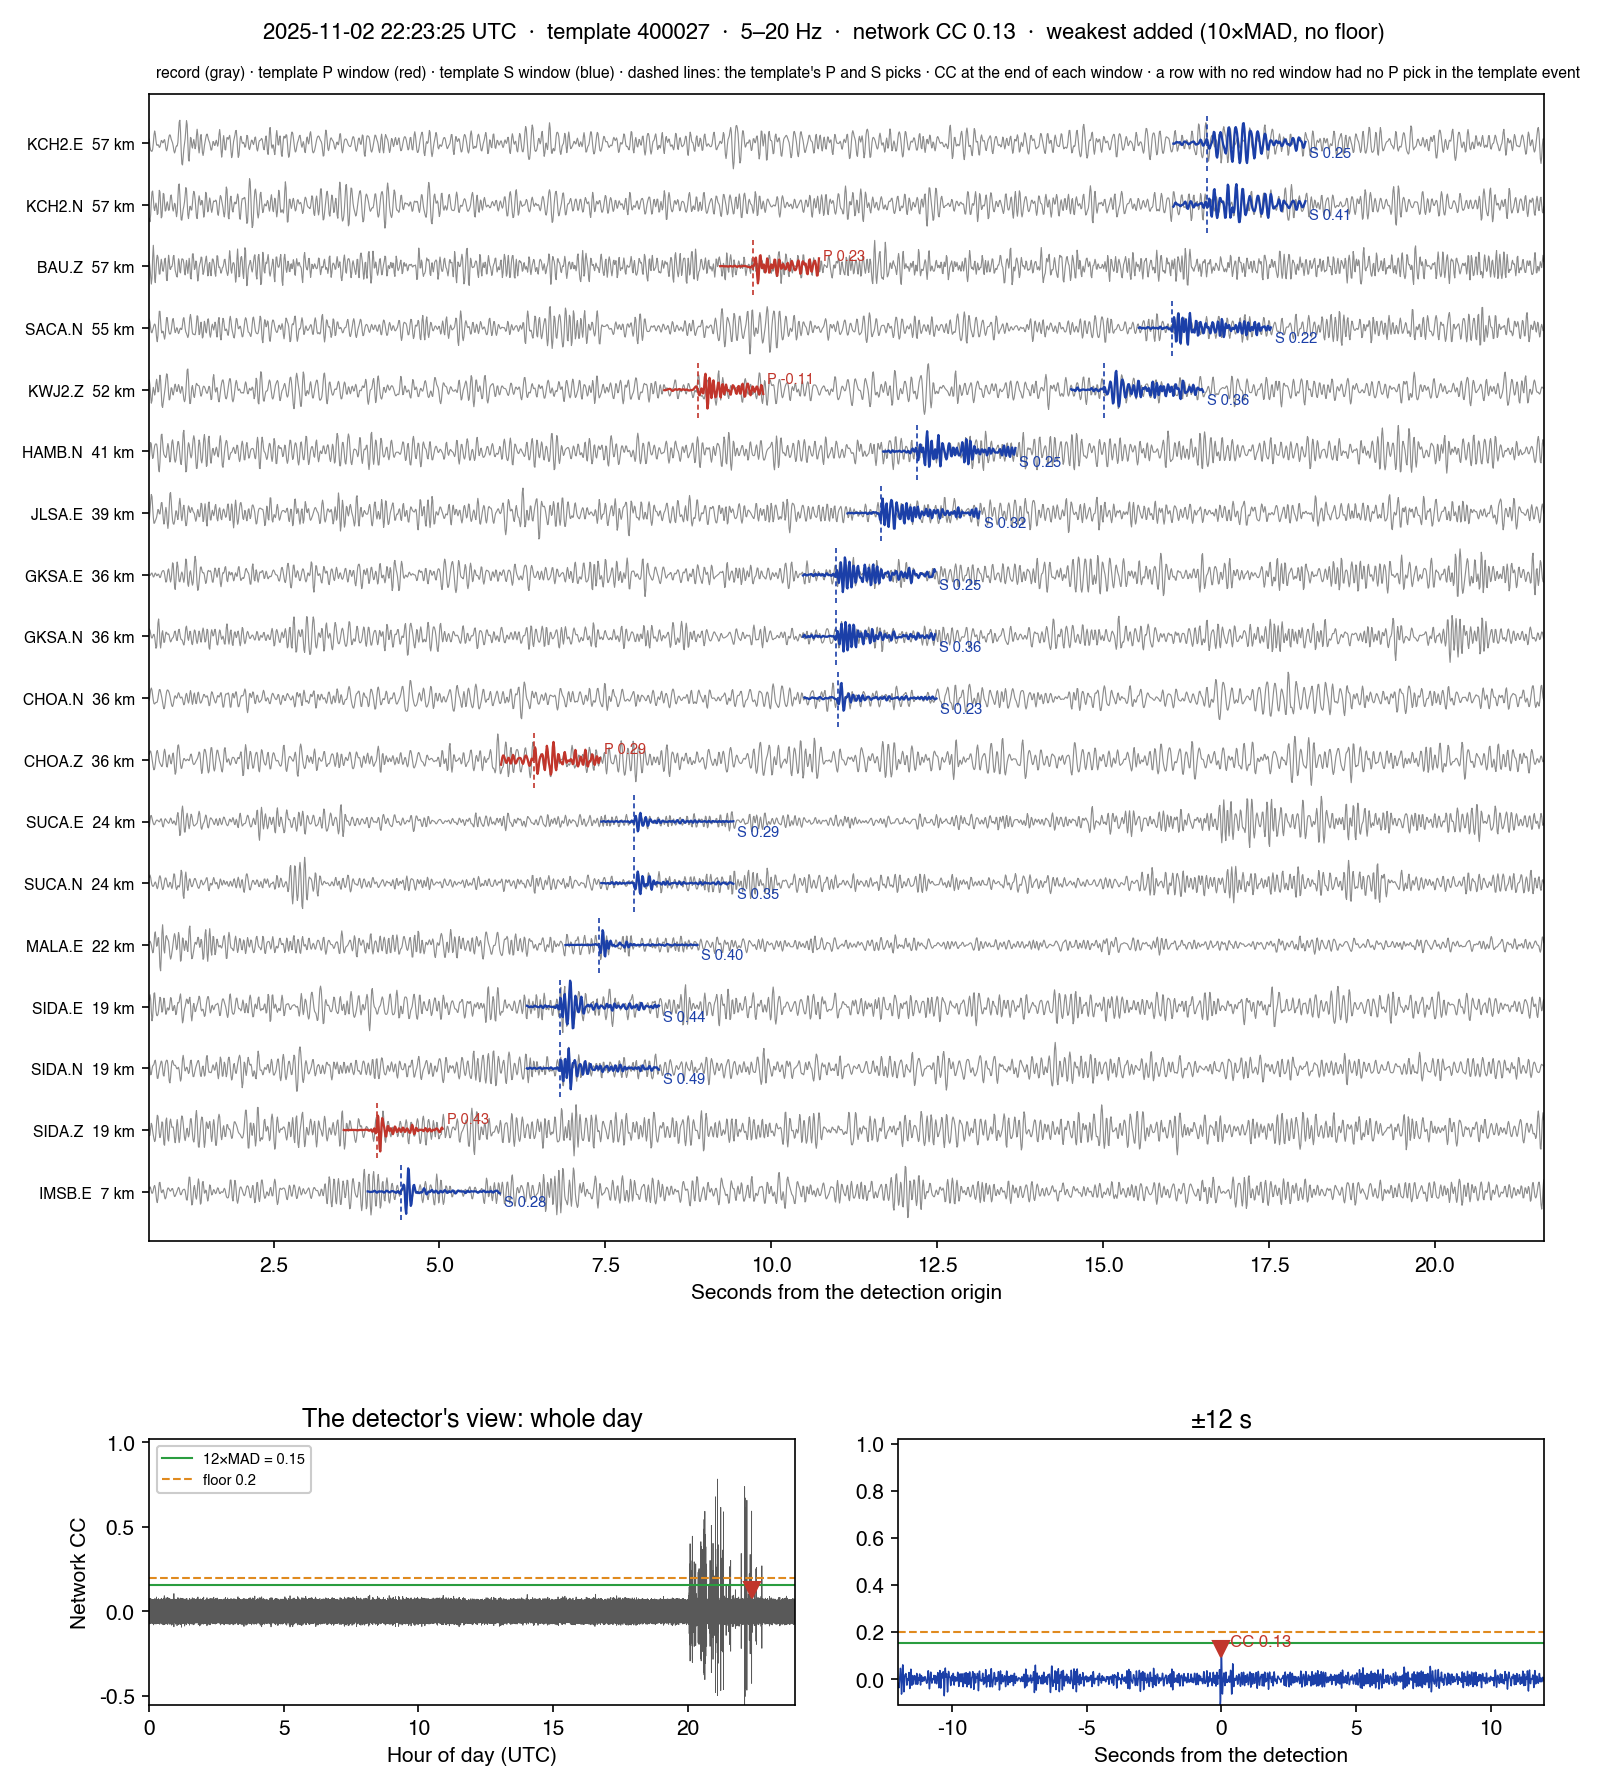

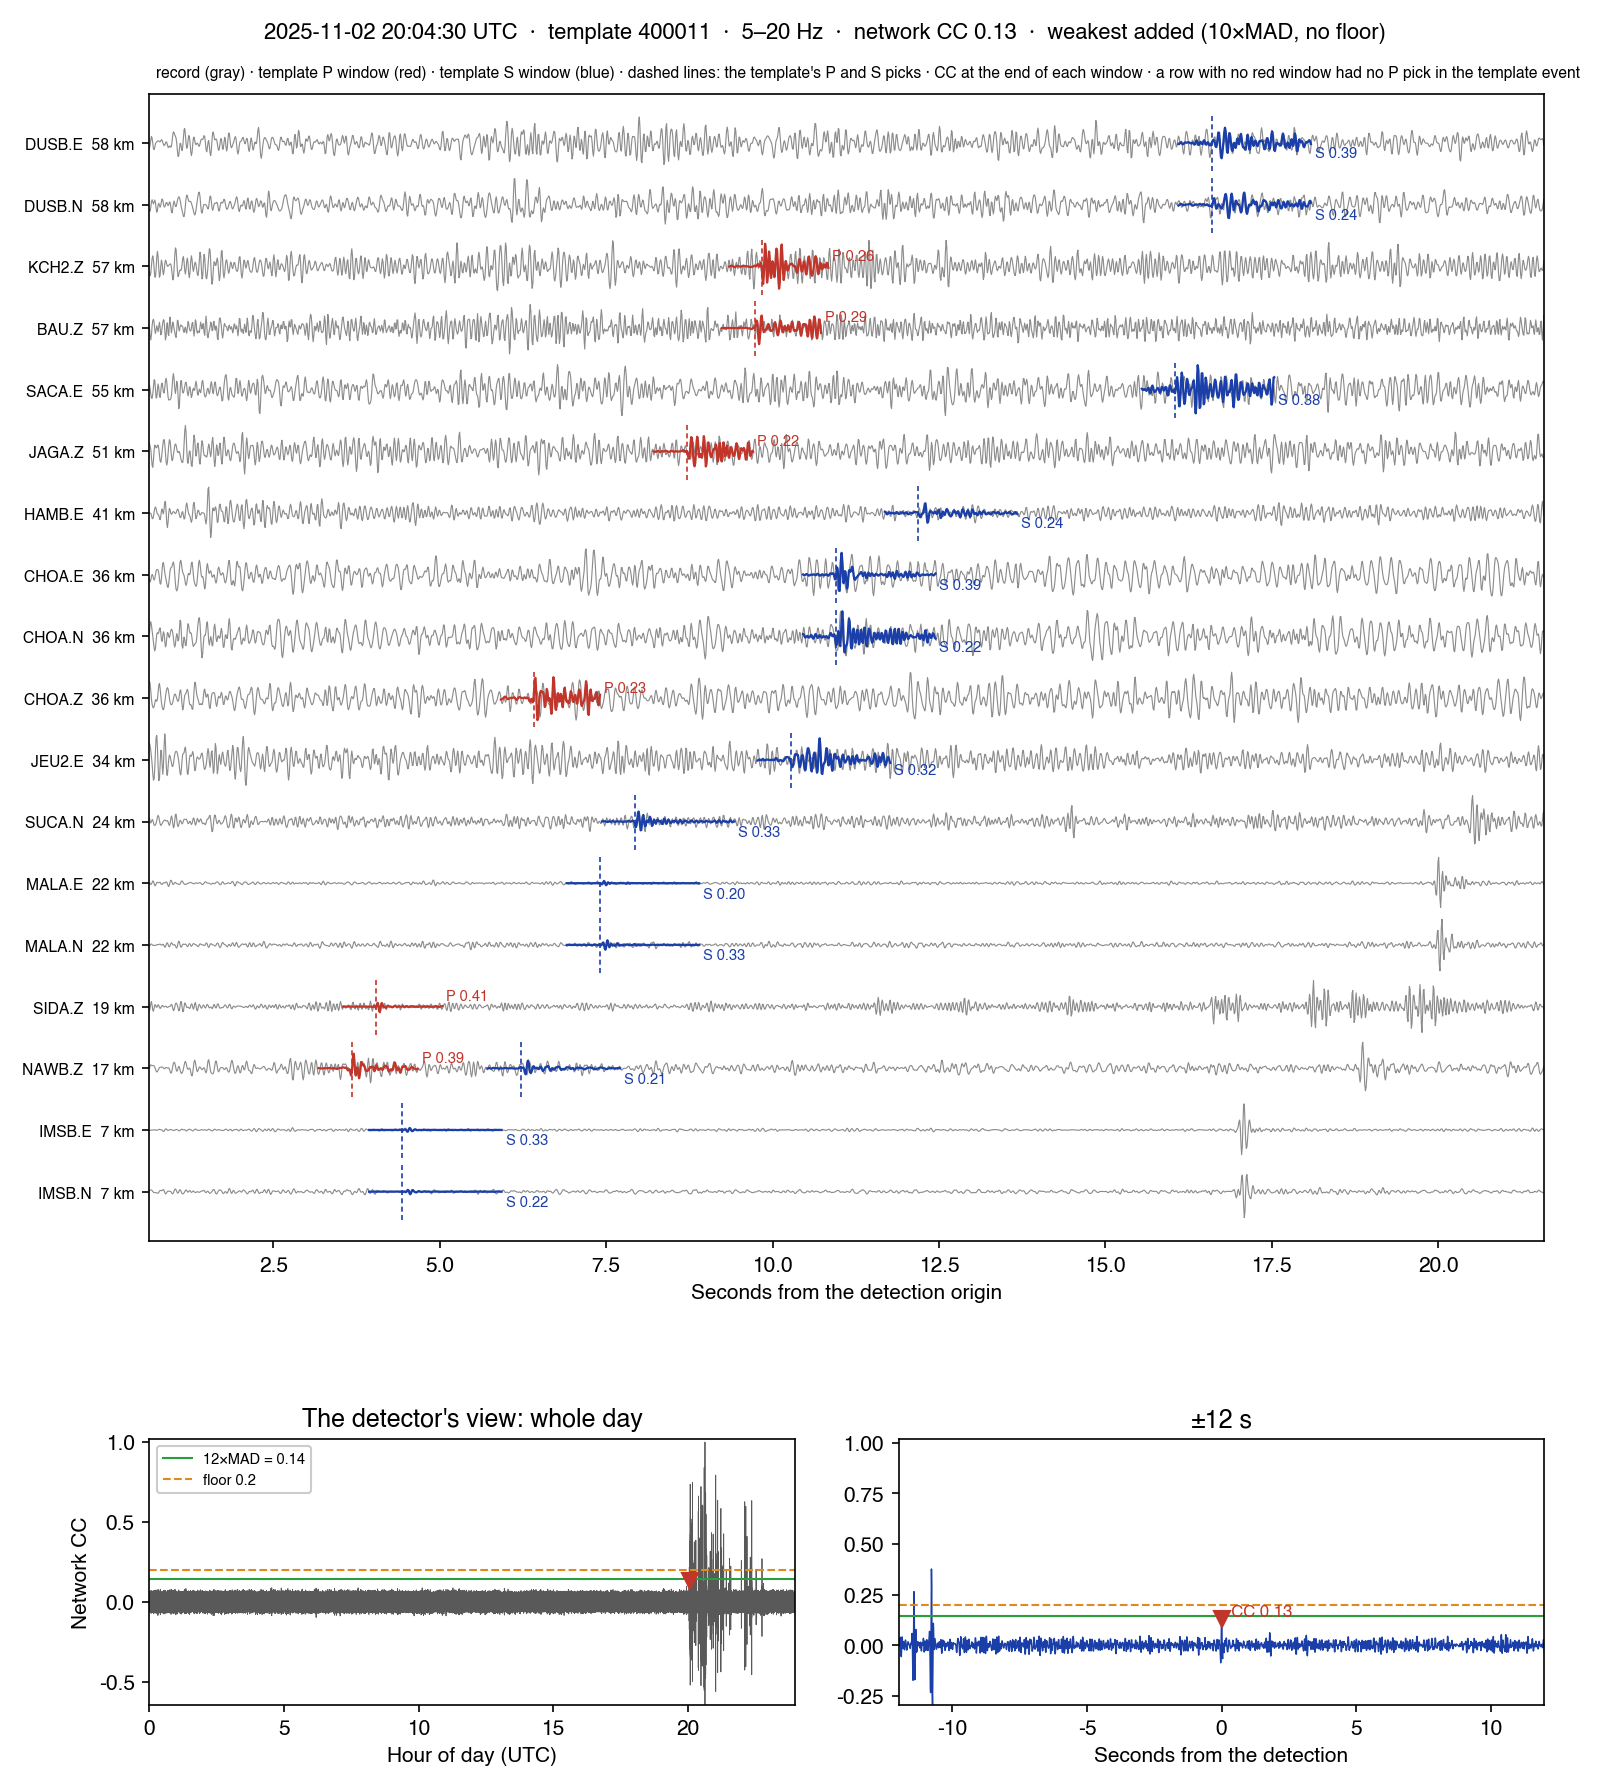

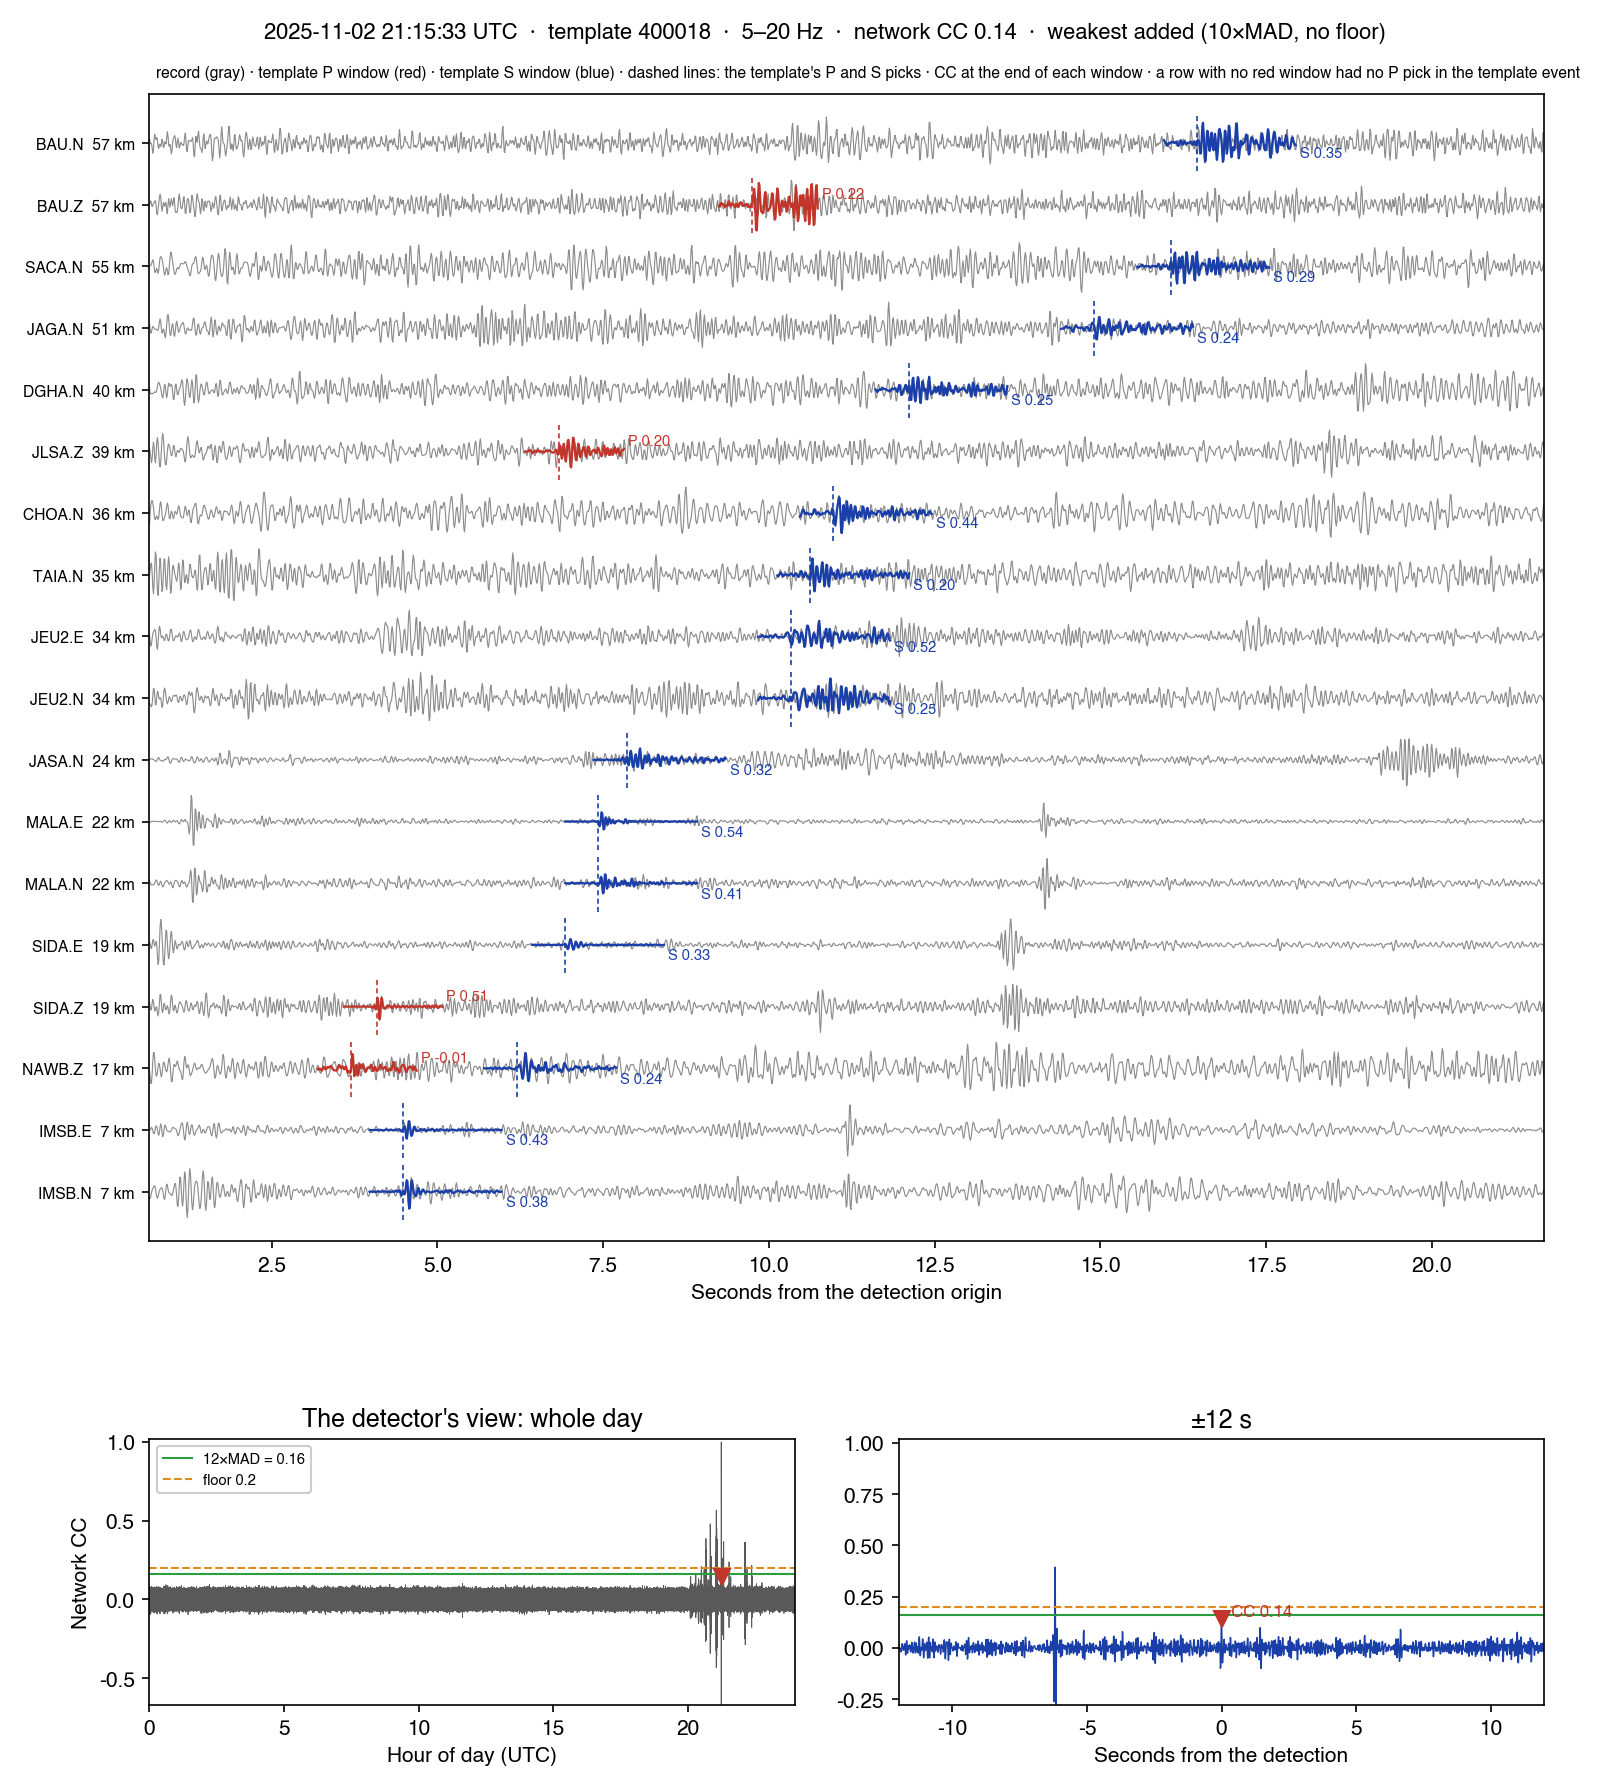

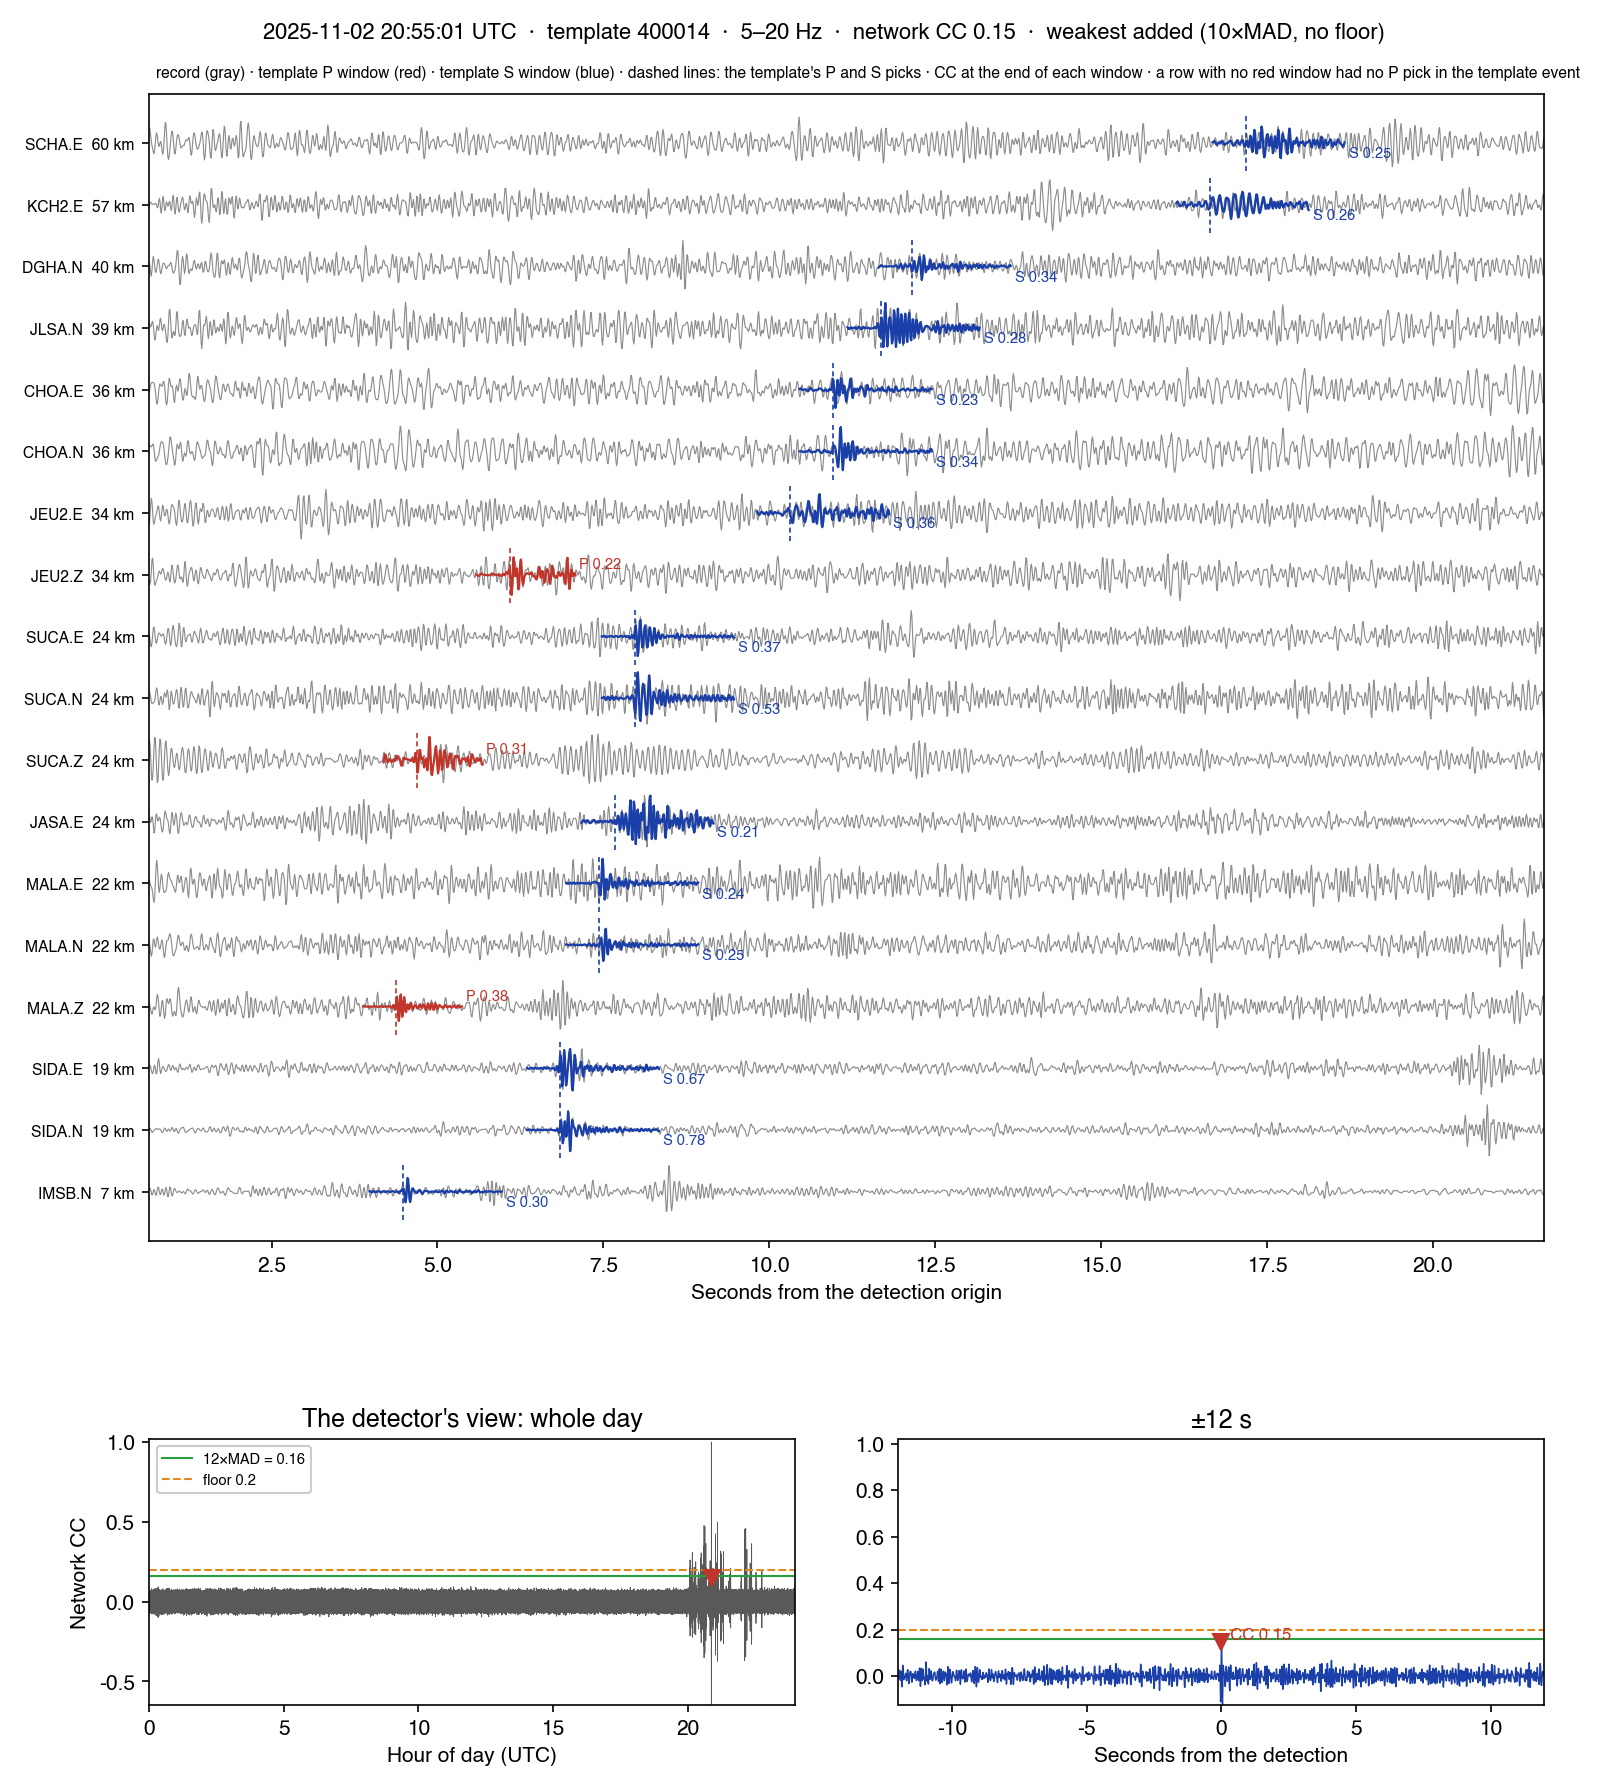

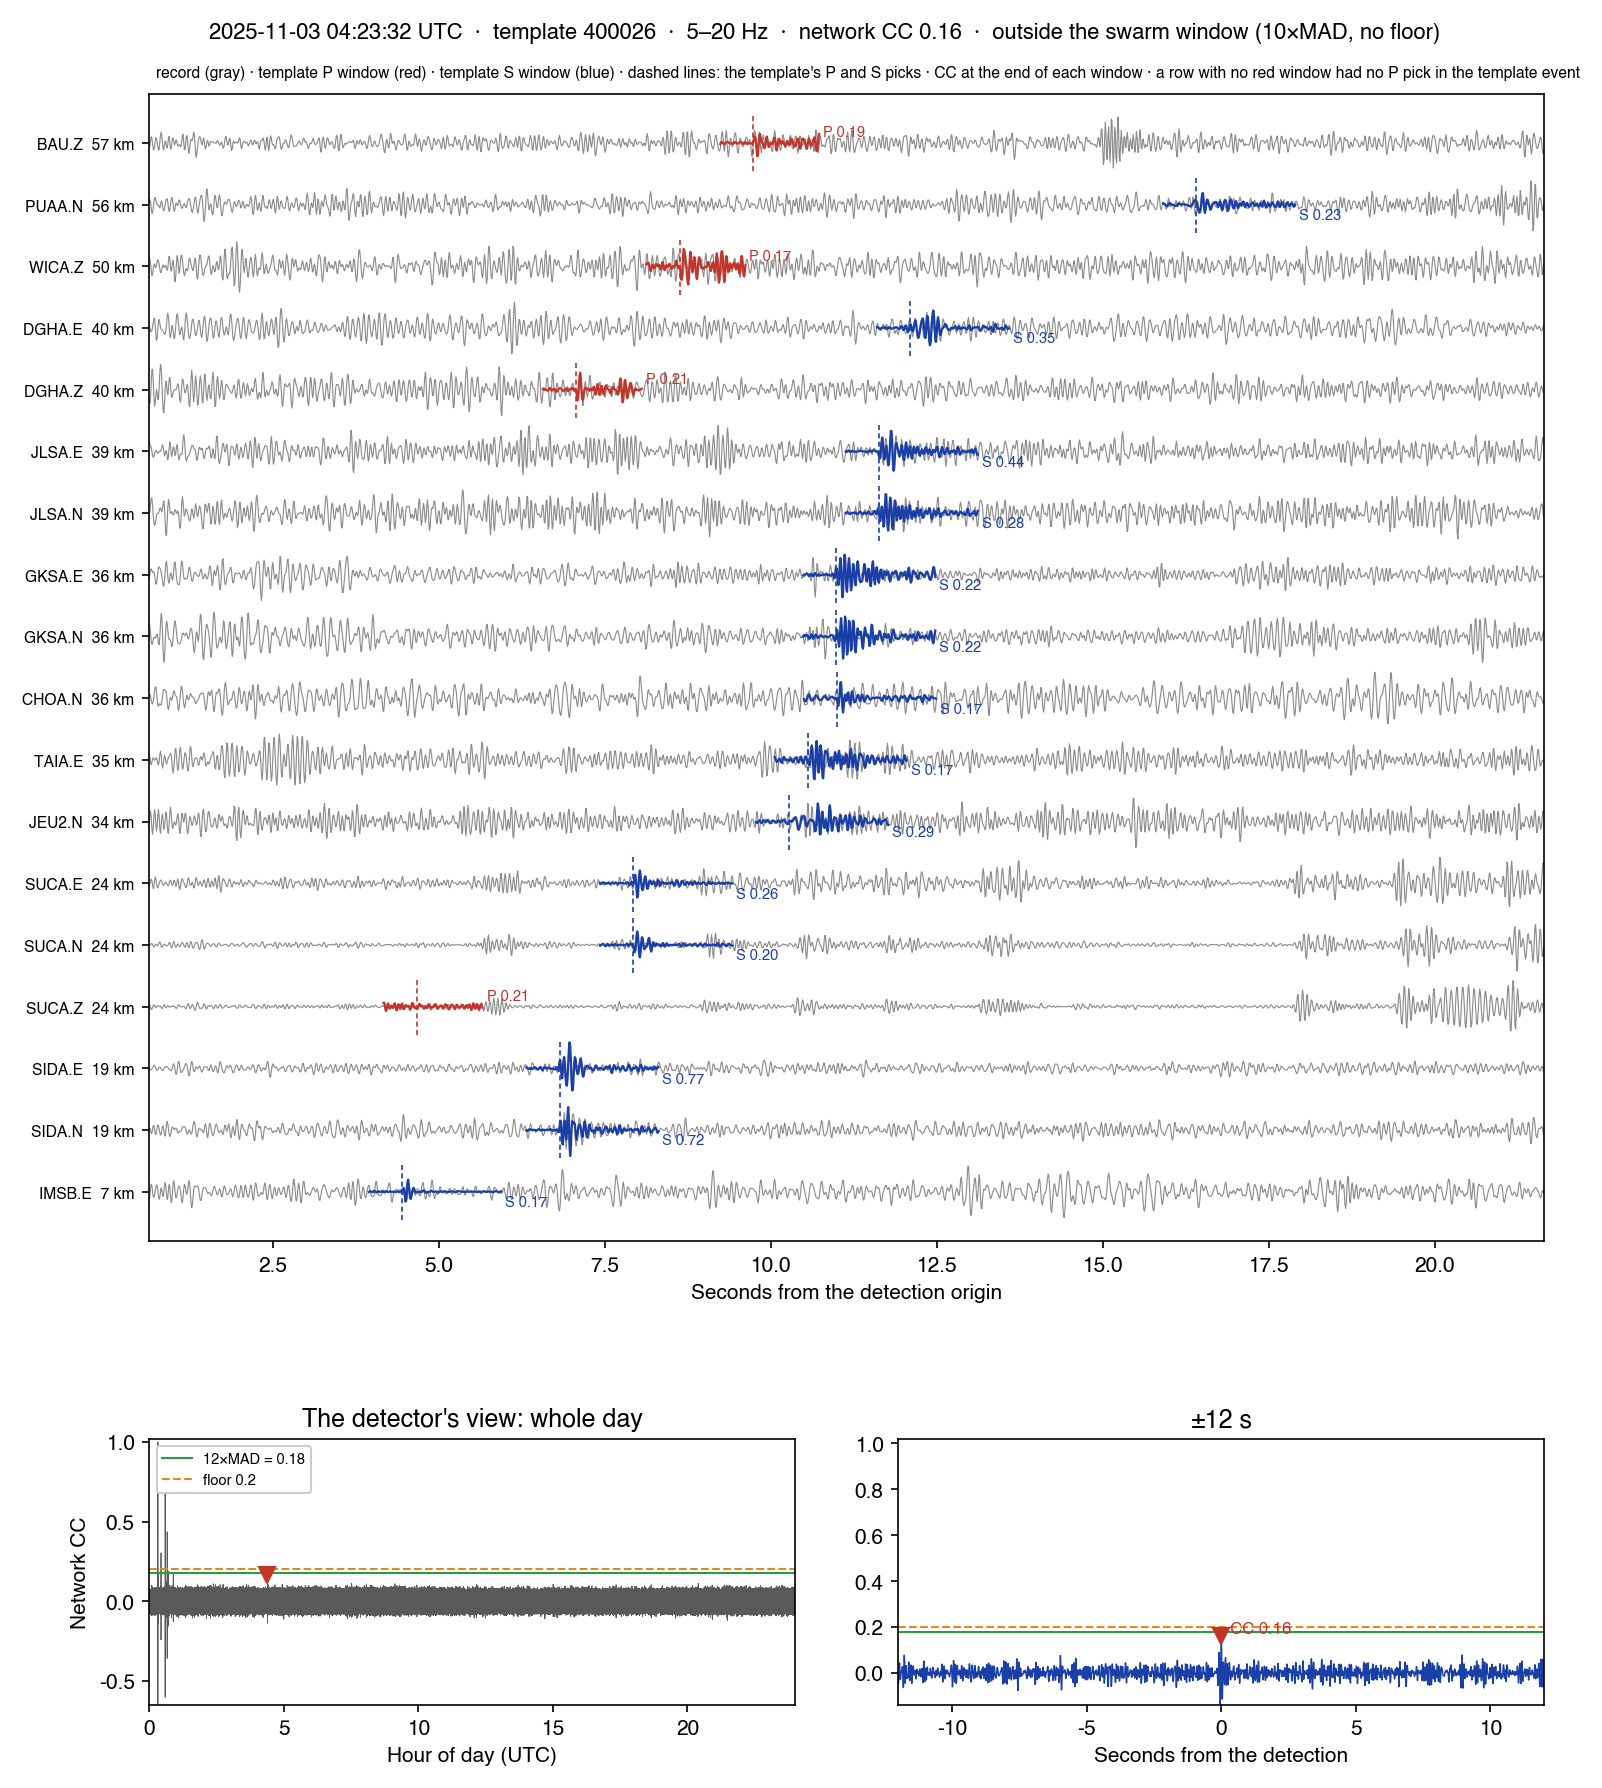

In [6]:
FIG = f'{DL}/notebooks/figs_09'; os.makedirs(FIG, exist_ok=True)
tpl_loc = pd.read_csv(f'{DL}/catalogs/imsil_templates_ref25.csv').set_index('cuspid'); band = f'{C.BANDPASS[0]:g}–{C.BANDPASS[1]:g} Hz'; DAYS = {(2025, 306): day306}
loose = cat['10×MAD, no floor']; show = [('weakest added (10×MAD, no floor)', r) for _, r in added['10×MAD, no floor'].sort_values('cc').head(4).iterrows()]
show += [('outside the swarm window (10×MAD, no floor)', r) for _, r in loose[~loose.origin.between(SW0, SW1)].head(6).iterrows()]
for lab, r in show:
    det = pd.Timestamp(r.origin); c = int(r.template_cuspid); k = cusp.index(c); lat, lon = tpl_loc.loc[c, ['latitude', 'longitude']]
    key = (det.year, det.dayofyear)
    if key not in DAYS: DAYS[key] = scan.load_day(stations, prefixes, det.year, det.dayofyear)
    day = DAYS[key]; ch, net, mean = S.detection_vs_template(sh, k, r.origin, present=day[1]); res = S.template_cc_day(sh, k, det.year, det.dayofyear, day=day)
    png = f'{FIG}/{det:%Y%m%d_%H%M%S}_{c}_set.png'
    S.plot_detection_set(sh, k, r.origin, ch, f'{det:%Y-%m-%d %H:%M:%S} UTC  ·  template {c}  ·  {band}  ·  network CC {net:.2f}  ·  {lab}', png, res=res, tpl_lat=lat, tpl_lon=lon)
    display(Image(png))

## Comprehensive summary

In [7]:
summary = pd.DataFrame([
    ('Templates identical across the two scans', same_tpl),
    ('Whole-day 12×MAD on 2025-11-02 below the 0.20 floor (templates)', f'{int((thr.t12 < 0.2).sum())} of {len(thr)}'),
    *[(f'{k}: detections (new) / outside the swarm window', f'{cnt.loc[k, "detections"]} ({cnt.loc[k, "new"]}) / {cnt.loc[k, "outside_swarm_window"]}') for k in VAR],
    *[(f'Picks above chance (median; share >= 3): {k}', f'{tab.loc[k, "median_excess"]:.2f}; {tab.loc[k, "share_excess_ge3"]:.2f}') for k in tab.index],
], columns=['quantity', 'value'])
display(summary)
print('Evidence only. Which threshold the Imsil FMF catalog uses is decision D23 (user).')

,quantity,value
0,Templates identical across the two scans,True
1,Whole-day 12×MAD on 2025-11-02 below the 0.20 ...,17 of 28
2,"current (12×MAD, floor 0.20): detections (new)...",187 (159) / 0
3,"12×MAD, no floor: detections (new) / outside t...",194 (166) / 0
4,"10×MAD, floor 0.20: detections (new) / outside...",210 (182) / 0
5,"10×MAD, no floor: detections (new) / outside t...",235 (207) / 1
6,Picks above chance (median; share >= 3): curre...,2.75; 0.47
7,Picks above chance (median; share >= 3): added...,0.00; 0.14
8,Picks above chance (median; share >= 3): added...,0.00; 0.00
9,Picks above chance (median; share >= 3): added...,0.00; 0.02


Evidence only. Which threshold the Imsil FMF catalog uses is decision D23 (user).
